In [1]:
from anemone.forwards import *
from anemone.experiment import Loop, Receiver
import torch
t = torch.logspace(-5, -3, 31)
tx = Loop.square(40)
rx = Receiver()
fwr = Forward.colecole(tx, rx, t)

In [12]:
rho = torch.tensor([40, 40, 40])
phi = 1/torch.tensor([0, 120, 240])
tau = torch.tensor([0.1, 0.2, 0.3])
c   = torch.tensor([0.1, 0.2, 0.3])
thk = torch.tensor([20,40])
dbdt = fwr(rho, phi, tau, c, thk)

c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:274: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\TensorShape.cpp:3618.)
  return HR.T.squeeze()


In [33]:
import numpy as np
import matplotlib.pyplot as plt

def colecole(rho_o, tau, m, c, omega):
    """equation 1 from Pelton et al. 1978
    """
    tmp = 1.+(1j*omega*tau)**c
    tmp = 1. - 1./tmp
    tmp = 1. - m*tmp
    rho = rho_o*tmp
    return rho

def mpa2cc(rho, phi_max, tau_phi, C):
    n = 0
    m0 = torch.zeros_like(phi_max)
    m_new = torch.ones_like(phi_max)
    
    tan_phi = torch.tan(-phi_max)

    while torch.all(torch.abs(m_new-m0)/m_new > 1e-3) and n < 10:
        if n>0: m0 = m_new*1.
        tau_cc = tau_phi*(1.-m0)**(-0.5/C)
        ab = 1./(1.+(1j*tau_cc/tau_phi)**C)
        m_new = tan_phi / ((1.-ab.real)*tan_phi + ab.imag)
        n += 1
    return rho, tau_cc, m_new, C

def cc2mpa(rho, tau_cc, m, C):
    tau_phi = tau_cc * (1-m)**(0.5/C)
    rho_cmplx = colecole(rho, tau_cc, m, C, 1./tau_phi)
    phi_max =  -torch.arctan(rho_cmplx.imag/rho_cmplx.real)
    return rho, phi_max, tau_phi, C   

rho = torch.ones(1)*100.
tau = torch.ones(1)*0.1
m0  = torch.ones(1)*0.54
C   = torch.ones(1)*0.2

rho1, phi_max, tau_phi, C1 = cc2mpa(rho, tau, m0, C)
rho2,tau2, m2, C2 = mpa2cc(rho1, phi_max, tau_phi, C1)
print(f'rho: {rho}->{rho1}->{rho2}')
print(f'tau: {tau}->{tau_phi}->{tau2}')
print(f'm: {m0}->{phi_max}->{m2}')
print(f'C: {C}->{C1}->{C2}')


rho: tensor([100.])->tensor([100.])->tensor([100.])
tau: tensor([0.1000])->tensor([0.0144])->tensor([0.1000])
m: tensor([0.5400])->tensor([0.0607])->tensor([0.5400])
C: tensor([0.2000])->tensor([0.2000])->tensor([0.2000])


In [ ]:
def colecole(rho_o, m, tau, c, omega):
    """equation 1 from Pelton et al. 1978
    """
    tmp = 1.+(1j*omega*tau)**c
    tmp = 1. - 1./tmp
    tmp = 1. - m*tmp
    rho = rho_o*tmp
    return rho

def mpa2colecole(rho, phi_max, tau_phi, C):
    n = 0
    m0 = torch.zeros_like(phi_max)
    m_new = torch.ones_like(phi_max)
    
    tan_phi = torch.tan(-phi_max)

    while torch.all(torch.abs(m_new-m0)/m_new > 1e-6) and n < 10:
        if n>0: m0 = m_new*1.
        tau_cc = tau_phi*(1.-m0)**(-0.5*C)
        ab = 1./(1.+(1j*tau_cc/tau_phi)**C)
        m_new = tan_phi / ((1.-ab.real)*tan_phi + ab.imag)
        n += 1
    print(n)
    return rho, tau_cc, m_new, C

def colecole2mpa(rho, tau_cc, m, C):
    tau_phi = tau_cc * (1-m)**(0.5*C)
    rho_cmplx = colecole(rho, m, tau_cc, C, 1./tau_phi)
    phi_max =  -torch.arctan(rho_cmplx.imag/rho_cmplx.real)
    return rho, phi_max, tau_phi, C  

rho  = torch.tensor([4.0e+02, 4.0e+02, 5.0e+02], dtype=torch.double)
m0   = torch.tensor([2.0e+02, 9.0e+02, 5.0e+02], dtype=torch.double)*1e-3
tau  = torch.tensor([1.0e-04, 2.0e-04, 3.0e-04], dtype=torch.double)
C  = torch.tensor([6.0e-01, 5.0e-01, 9.0e-01], dtype=torch.double)

thick = torch.tensor([20, 40], dtype=torch.double)


rho1, phi_max, tau_phi, C1 = colecole2mpa(rho, tau, m0, C)
rho2,tau2, m2, C2 = mpa2colecole(rho1, phi_max, tau_phi, C1)
print(f'rho: {rho}->{rho1}->{rho2}')
print(f'tau: {tau}->{tau_phi}->{tau2}')
print(f'm: {m0}->{phi_max}->{m2}')
print(f'C: {C}->{C1}->{C2}')


4
rho: tensor([400., 400., 500.], dtype=torch.float64)->tensor([400., 400., 500.], dtype=torch.float64)->tensor([400., 400., 500.], dtype=torch.float64)
tau: tensor([0.0001, 0.0002, 0.0003], dtype=torch.float64)->tensor([9.3525e-05, 1.1247e-04, 2.1961e-04], dtype=torch.float64)->tensor([0.0001, 0.0002, 0.0003], dtype=torch.float64)
m: tensor([0.2000, 0.9000, 0.5000], dtype=torch.float64)->tensor([0.0567, 0.3659, 0.2905], dtype=torch.float64)->tensor([0.2000, 0.8994, 0.5000], dtype=torch.float64)
C: tensor([0.6000, 0.5000, 0.9000], dtype=torch.float64)->tensor([0.6000, 0.5000, 0.9000], dtype=torch.float64)->tensor([0.6000, 0.5000, 0.9000], dtype=torch.float64)


In [57]:
rho = torch.ones(1)*100.
tau_phi = torch.ones(1)*0.1
phi_max  = torch.ones(1)*0.0054
C   = torch.ones(1)*0.2

rho1,tau2, m2, C1 = mpa2colecole(rho, phi_max, tau_phi, C)
rho2, phi_max2, tau_phi2, C2 = colecole2mpa(rho1, tau2, m2, C1)

print(f'rho: {rho}->{rho1}->{rho2}')
print(f'tau: {tau_phi}->{tau2}->{tau_phi2}')
print(f'm: {phi_max}->{m2}->{phi_max2}')
print(f'C: {C}->{C1}->{C2}')


2
rho: tensor([100.])->tensor([100.])->tensor([100.])
tau: tensor([0.1000])->tensor([0.1007])->tensor([0.1000])
m: tensor([0.0054])->tensor([0.0659])->tensor([0.0054])
C: tensor([0.2000])->tensor([0.2000])->tensor([0.2000])


In [45]:
print('rho: \t', rho1)
print('phi_max: \t', phi_max)
print('tau_phi: \t', tau_phi)
print('C: \t', C1)

rho: 	 tensor([100.])
phi_max: 	 tensor([nan])
tau_phi: 	 tensor([0.1000])
C: 	 tensor([0.2000])


In [23]:
rho2,tau2, m2, C = mpa2cc(rho1, phi_max, tau_phi, C1)

In [24]:
print(rho2)
print(tau2)
print(m2)
print(C)

tensor([100., 100., 100.])
tensor([0.0182, 0.0182, 0.0182])
tensor([0.0897, 0.0897, 0.0897])
tensor([0.2000, 0.2000, 0.2000])


In [162]:
omega = np.linspace(1e-6, 1e6, 100)*2*np.pi
rho_omega = colecole(rho, m0, tau, C, omega)

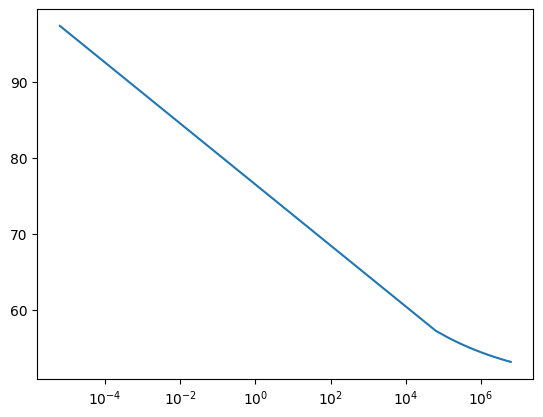

In [150]:
plt.figure()
plt.semilogx(omega, np.abs(rho_omega))

In [5]:
# def colecole(rho_o, m, tau, c, omega):
#     """equation 1 from Pelton et al. 1978
#     """
#     tmp = 1.+(1j*omega*tau)**c
#     tmp = 1. - 1./tmp
#     tmp = 1. - m*tmp
#     rho = rho_o*tmp
#     return rho

# def mpa2colecole(rho, phi_max, tau_phi, C):
#     n = 0
#     m0 = torch.zeros_like(phi_max)
#     m_new = torch.ones_like(phi_max)
    
#     tan_phi = torch.tan(-phi_max)

#     while torch.all(torch.abs(m_new-m0)/m_new > 1e-6) and n < 10:
#         if n>0: m0 = m_new*1.
#         tau_cc = tau_phi*(1.-m0)**(-0.5*C)
#         ab = 1./(1.+(1j*tau_cc/tau_phi)**C)
#         m_new = tan_phi / ((1.-ab.real)*tan_phi + ab.imag)
#         n += 1
#     print(n)
#     return rho, tau_cc, m_new, C

# def colecole2mpa(rho, tau_cc, m, C):
#     tau_phi = tau_cc * (1-m)**(0.5*C)
#     rho_cmplx = colecole(rho, m, tau_cc, C, 1./tau_phi)
#     phi_max =  -torch.arctan(rho_cmplx.imag/rho_cmplx.real)
#     return rho, phi_max, tau_phi, C  

rho  = torch.tensor([4.0e+02, 4.0e+02, 5.0e+02], dtype=torch.double)
m0   = torch.tensor([2.0e+02, 9.0e+02, 5.0e+02], dtype=torch.double)*1e-3
tau  = torch.tensor([1.0e-04, 2.0e-04, 3.0e-04], dtype=torch.double)
C  = torch.tensor([6.0e-01, 5.0e-01, 9.0e-01], dtype=torch.double)

thick = torch.tensor([20, 40], dtype=torch.double)

In [33]:
from anemone.forwards import *
from anemone.experiment import Loop, Receiver, Waveform
import torch
t = torch.logspace(-5, -3, 31)
tx = Loop.square(40)
rx = Receiver()

In [50]:
#rho  = torch.tensor([4.0e+02, 4.0e+02, 5.0e+02], dtype=torch.double)
rho = torch.tensor([40, 40, 40])/4
m0   = torch.tensor([2.0e+02, 9.0e+02, 5.0e+02], dtype=torch.double)*1e-8
tau  = torch.tensor([1.0e-04, 2.0e-04, 3.0e-04], dtype=torch.double)
C  = torch.tensor([6.0e-01, 5.0e-01, 9.0e-01], dtype=torch.double)

thick = torch.tensor([20, 40], dtype=torch.double)

In [51]:
fwrTDcc = Forward.colecole(tx, rx,   t, waveform=Waveform.example())
fwrFDcc = ForwardFD.colecole(tx, rx, torch.logspace(2, 6, 32))

fwrTD = Forward(tx, rx, t, waveform=Waveform.example())
fwrFD = ForwardFD(tx, rx, torch.logspace(2, 6, 32))


c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


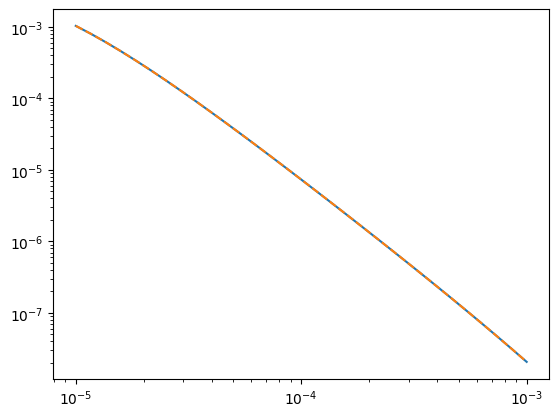

In [54]:
dbdt_cc = fwrTDcc(rho, m0, tau, C, thick)
dbdt    = fwrTD(rho, thick)

fig = plt.figure()
plt.loglog(t, dbdt_cc.numpy())
# plt.loglog(t, -dbdt_cc.numpy(), 'C0--')
plt.loglog(t,  dbdt.numpy(), 'C1--')
# plt.loglog(t, -dbdt.numpy(), 'C1--')

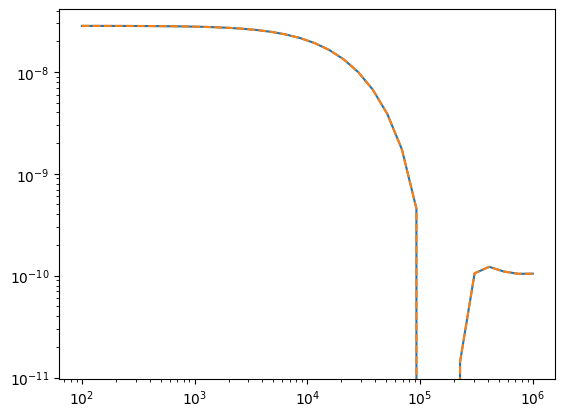

In [ ]:
dbdt_cc = fwrFDcc(rho, m0, tau, C, thick)
dbdt    = fwrFD(rho, thick)

fig = plt.figure()
plt.loglog(fwrFD.freqs,  dbdt_cc.numpy())
# plt.loglog(t, -dbdt_cc.numpy(), 'C0--')
plt.loglog(fwrFD.freqs,   dbdt.numpy(), 'C1--')
# plt.loglog(t, -dbdt.numpy(), 'C1--')